# [drosophila_body_orientation_predictor](https://github.com/nehalsinghmangat/drosophila_body_orientation_predictor) — Training and Testing the ANN

This notebook selects, trains and tests the heading-prediction neural network on the corrected data produced by `01_data_correction_and_processing.ipynb` (`../trainingdata/04_trainingdata/`).

1. **Training.** Architecture search (grouped cross-validation), then the final model.
2. **Testing.** Held-out evaluation overall and by flight regime (upwind / crosswind / downwind); robustness across training seeds; leave-one-wind-speed-out generalisation; error against trajectory covariates.
3. **Confidence.** Ensemble-agreement confidence signal and out-of-range input warnings.
4. **Performance and errors.** The trained ANN on held-out trajectories: an example against the best linear (Möbius) predictor, and error against slip angle, ensemble agreement and training-set membership.

The comparison with linear/circular baselines (and, consequently, the case for using an ANN at all) can be found in `03_ann_vs_linear_models.ipynb`, which reads the results saved here. All results are written as CSVs to `../tables/`; trained models are written to `../models/`.

**Training vs. loading.** With `RETRAIN = True` (set in the setup cell) the notebook runs the architecture search and trains every model, which is slow. With `RETRAIN = False` (the default) it loads the saved models from `../models/` and only evaluates them; the architecture search, and so `architecture_cv_results.csv` (Table 6), is produced only when `RETRAIN = True`.

## Setup

In [1]:
import os
import sys
import random
import warnings
warnings.filterwarnings('ignore')

# TensorFlow must load before pandas: pandas loads pyarrow, whose bundled abseil then takes over TensorFlow's
# mutex code and model.fit / model.predict deadlock (the kernel sits at 0% CPU).
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

sys.path.insert(0, os.path.abspath('../utils'))
from utils import circular_distance

RANDOM_SEED = 42
# True: run the architecture search and train every model (slow). False: load the saved models from ../models/ and only evaluate them.
RETRAIN = True
np.random.seed(RANDOM_SEED)
os.makedirs('../trainingdata/04_trainingdata', exist_ok=True)

final_all_fly_data = pd.read_csv('../trainingdata/04_trainingdata/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv')
print(f"{len(final_all_fly_data)} frames, {final_all_fly_data['trajec_objid'].nunique()} trajectories")

# Trajectory-grouped train/test split -- no trajectory appears on both sides
traj_ids = final_all_fly_data['trajec_objid'].unique()
gss = GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=RANDOM_SEED)
train_idx, test_idx = next(gss.split(np.zeros((len(traj_ids), 1)), groups=traj_ids))
train_ids = set(traj_ids[train_idx])
test_ids = set(traj_ids[test_idx])
train_df = final_all_fly_data[final_all_fly_data['trajec_objid'].isin(train_ids)].reset_index(drop=True)
test_df = final_all_fly_data[final_all_fly_data['trajec_objid'].isin(test_ids)].reset_index(drop=True)
print(f"Train: {len(train_df)} frames ({len(train_ids)} trajectories)")
print(f"Test:  {len(test_df)} frames ({len(test_ids)} trajectories)")


def classify_direction(angle_rad):
    # Wind blows toward +x, so upwind = -x: an angle within 45 deg of 0 is downwind, within 45 deg of 180 is upwind.
    # Regimes are classified by course (groundspeed_angle, the direction of travel), which is known at inference time.
    deg = np.degrees(np.arctan2(np.sin(angle_rad), np.cos(angle_rad)))
    return np.where(
        np.abs(deg) <= 45, 'downwind',
        np.where(np.abs(np.abs(deg) - 180) <= 45, 'upwind', 'crosswind')
    )

112083 frames, 3321 trajectories
Train: 75141 frames (2225 trajectories)
Test:  36942 frames (1096 trajectories)


## Inputs, features and augmentation

The network takes the current frame's groundspeed and airspeed, each as magnitude and direction (four inputs total). Its target is the heading direction as the unit vector $(\cos\theta_t, \sin\theta_t)$, stored in the dataframe as `heading_angle_x` and `heading_angle_y`. Thrust is not an input, because the heading correction itself is referenced to the thrust direction (this prevents the potential circularity of the predictor predicting the heading correction). Wind-rotation augmentation is applied to the training trajectories after the train-test split.

## Model Training

### Splitting the Data 

In [2]:
import random
import keras
from sklearn.model_selection import GroupShuffleSplit

from utils import pull_out_individual_trajectories, augment_trajectories, create_model, geodesic_loss, trajectory_length_sample_weights

random.seed(RANDOM_SEED)

fly_traj_list = pull_out_individual_trajectories(final_all_fly_data, min_traj_length=12)
train_trajectories = [t for t in fly_traj_list if t['trajec_objid'].iloc[0] in train_ids]
test_trajectories = [t for t in fly_traj_list if t['trajec_objid'].iloc[0] in test_ids]
print(f"Train: {len(train_trajectories)} trajectories   Test: {len(test_trajectories)} trajectories")

ann_input_names = ['groundspeed', 'groundspeed_angle', 'airspeed', 'airspeed_angle']
n_input = len(ann_input_names)
n_output = 2
KEEP_COLS = ['heading_angle_x', 'heading_angle_y', 'trajec_objid']


train_original = augment_trajectories(train_trajectories, input_names=ann_input_names, output_names=KEEP_COLS)
train_wind = augment_trajectories(train_trajectories, input_names=ann_input_names, output_names=KEEP_COLS, wind_augment=True, wrap_angles=True)
train_all = pd.concat([train_original, train_wind], ignore_index=True)
test_embedded = augment_trajectories(test_trajectories, input_names=ann_input_names, output_names=KEEP_COLS)

print(f"Train rows (original + rotated): {len(train_all):,}")
print(f"Test rows (unaugmented, held out): {len(test_embedded):,}")

Detected 3321 trajectories.
3321 trajectories with more than 12 timesteps.
Train: 2225 trajectories   Test: 1096 trajectories


Train rows (original + rotated): 150,282
Test rows (unaugmented, held out): 36,942


#### Selecting the Architecture
The loss is `utils.geodesic_loss`, the true angular distance between predicted and target headings (`arccos` of the dot product, epsilon-clipped for stability). Each frame is weighted by `utils.trajectory_length_sample_weights` (`1/len(its trajectory)`): frame-level losses implicitly weight long trajectories more heavily because they contribute more rows, while the evaluation convention (median error per trajectory) weights every trajectory equally.

The architecture is chosen by sweeping 1-3 hidden layers x 10, 15, 20 or 30 neurons with trajectory-grouped 3-fold cross-validation on the training trajectories, with wind-rotation augmentation applied to each fold's training portion. Error is the out-of-fold median per-trajectory angular error; the configuration with the lowest error is used for the final model. The selected configuration is 3 hidden layers of 30 ReLU units each, followed by a 2-unit linear layer and a unit-normalization layer, so the output is a unit heading vector.

In [3]:
from sklearn.model_selection import GroupKFold

def angular_error_deg(y_true_xy, y_pred_xy):
    true_angle = np.arctan2(y_true_xy[:, 1], y_true_xy[:, 0])
    pred_angle = np.arctan2(y_pred_xy[:, 1], y_pred_xy[:, 0])
    return np.degrees(circular_distance(true_angle, pred_angle))


def per_trajectory_errors(ids, err):
    return pd.DataFrame({'trajec_objid': ids, 'err': err}).groupby('trajec_objid')['err'].median()


def bootstrap_ci(values, n_boot=5000, ci=95, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boots = rng.choice(values, size=(n_boot, len(values)), replace=True)
    boot_medians = np.median(boots, axis=1)
    lo, hi = np.percentile(boot_medians, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return float(np.median(values)), float(lo), float(hi)


ARCH_CANDIDATES = [(layers, neurons) for layers in [1, 2, 3] for neurons in [10, 15, 20, 30]]

if RETRAIN:
    train_traj_ids_cv = np.array(sorted({t['trajec_objid'].iloc[0] for t in train_trajectories}))
    gkf = GroupKFold(n_splits=3)
    fold_splits = list(gkf.split(np.zeros((len(train_traj_ids_cv), 1)), groups=train_traj_ids_cv))
    traj_by_id_cv = {t['trajec_objid'].iloc[0]: t for t in train_trajectories}

    sweep_rows = []
    for layers, neurons in ARCH_CANDIDATES:
        oof_ids, oof_errs = [], []
        for subtrain_idx, val_idx in fold_splits:
            subtrain_trajs = [traj_by_id_cv[i] for i in train_traj_ids_cv[subtrain_idx]]
            val_trajs = [traj_by_id_cv[i] for i in train_traj_ids_cv[val_idx]]

            sub_orig = augment_trajectories(subtrain_trajs, input_names=ann_input_names, output_names=KEEP_COLS)
            sub_wind = augment_trajectories(subtrain_trajs, input_names=ann_input_names, output_names=KEEP_COLS, wind_augment=True, wrap_angles=True)
            sub_all = pd.concat([sub_orig, sub_wind], ignore_index=True)
            val_embed = augment_trajectories(val_trajs, input_names=ann_input_names, output_names=KEEP_COLS)
            sample_weight = trajectory_length_sample_weights(sub_all['trajec_objid'].values)

            keras.utils.set_random_seed(RANDOM_SEED)
            m = create_model(n_input=n_input, n_output=n_output, neurons=neurons, layers=layers, loss=geodesic_loss)
            m.fit(sub_all.iloc[:, 0:n_input].values, sub_all[['heading_angle_x', 'heading_angle_y']].values,
                  sample_weight=sample_weight, epochs=150, batch_size=256, verbose=0)
            pred = m(val_embed.iloc[:, 0:n_input].values.astype('float32'), training=False).numpy()   # model.predict can deadlock when called many times
            err_cv = angular_error_deg(val_embed[['heading_angle_x', 'heading_angle_y']].values, pred)
            oof_ids.extend(val_embed['trajec_objid'].values)
            oof_errs.extend(err_cv)

        per_traj_cv = per_trajectory_errors(np.array(oof_ids), np.array(oof_errs))
        med_cv, lo_cv, hi_cv = bootstrap_ci(per_traj_cv.values)
        sweep_rows.append({'layers': layers, 'neurons': neurons, 'n_trajectories': len(per_traj_cv),
                           'cv_median_error': med_cv, 'cv_ci95_lo': lo_cv, 'cv_ci95_hi': hi_cv,
                           'cv_q25': np.percentile(per_traj_cv.values, 25), 'cv_q75': np.percentile(per_traj_cv.values, 75)})

    sweep_results = pd.DataFrame(sweep_rows).sort_values('cv_median_error').reset_index(drop=True)
    pd.set_option('display.width', 160)
    print(sweep_results.to_string(index=False))
    os.makedirs('../tables', exist_ok=True)
    sweep_results.to_csv('../tables/architecture_cv_results.csv', index=False)

    ARCH_LAYERS, ARCH_NEURONS = int(sweep_results.iloc[0]['layers']), int(sweep_results.iloc[0]['neurons'])
    print(f"\nSelected architecture: layers={ARCH_LAYERS}, neurons={ARCH_NEURONS}")
else:
    print('RETRAIN = False: skipping the architecture search (models are loaded from ../models/).')

 layers  neurons  n_trajectories  cv_median_error  cv_ci95_lo  cv_ci95_hi   cv_q25    cv_q75
      3       30            2225         5.148360    4.914010    5.488953 2.697175 12.695773
      3       20            2225         5.186514    4.911444    5.458843 2.743879 13.168966
      2       20            2225         5.257609    4.922459    5.609741 2.900329 13.449304
      2       30            2225         5.278515    4.954058    5.520710 2.766581 13.197833
      3       15            2225         5.334588    4.996613    5.664358 2.753488 13.182626
      2       15            2225         5.479998    5.244146    5.761679 3.010980 13.288507
      1       30            2225         5.528720    5.262674    5.837000 2.999370 13.988658
      2       10            2225         5.539929    5.277747    5.824078 3.096152 13.906982
      3       10            2225         5.552961    5.322200    5.834139 3.045749 13.704665
      1       15            2225         5.594668    5.254173    5.924

#### Training the Final Model

In [4]:
def grouped_inner_val_split(X, y, groups, val_fraction=0.2, seed=123):
    unique_groups = groups.unique()
    gss2 = GroupShuffleSplit(n_splits=1, test_size=val_fraction, random_state=seed)
    dummy = np.zeros((len(unique_groups), 1))
    subtrain_gidx, val_gidx = next(gss2.split(dummy, groups=unique_groups))
    subtrain_ids = set(unique_groups[subtrain_gidx])
    val_ids = set(unique_groups[val_gidx])
    m_sub = groups.isin(subtrain_ids)
    m_val = groups.isin(val_ids)
    return (X[m_sub].values, y[m_sub].values), (X[m_val].values, y[m_val].values)


X_train = train_all.iloc[:, 0:n_input].reset_index(drop=True)
y_train = train_all[['heading_angle_x', 'heading_angle_y']].reset_index(drop=True)
groups_train = train_all['trajec_objid'].reset_index(drop=True)

def grouped_inner_val_split_with_weights(X, y, groups, val_fraction=0.2, seed=123):
    unique_groups = groups.unique()
    gss2 = GroupShuffleSplit(n_splits=1, test_size=val_fraction, random_state=seed)
    dummy = np.zeros((len(unique_groups), 1))
    subtrain_gidx, val_gidx = next(gss2.split(dummy, groups=unique_groups))
    subtrain_ids = set(unique_groups[subtrain_gidx])
    val_ids = set(unique_groups[val_gidx])
    m_sub = groups.isin(subtrain_ids)
    m_val = groups.isin(val_ids)
    sw_sub = trajectory_length_sample_weights(groups.values)[m_sub.values]
    return (X[m_sub].values, y[m_sub].values, sw_sub), (X[m_val].values, y[m_val].values)


def load_saved_model(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found; set RETRAIN = True to train it")
    return keras.models.load_model(path, compile=False)


CANONICAL_PATH = '../models/ann_model.keras'

if RETRAIN:
    keras.utils.set_random_seed(RANDOM_SEED)
    (Xtr, ytr, sw_tr), (Xval, yval) = grouped_inner_val_split_with_weights(X_train, y_train, groups_train)
    model = create_model(n_input=n_input, n_output=n_output, neurons=ARCH_NEURONS, layers=ARCH_LAYERS, loss=geodesic_loss)
    model.fit(Xtr, ytr, sample_weight=sw_tr, validation_data=(Xval, yval), epochs=150, batch_size=256, verbose=0)
    os.makedirs('../models', exist_ok=True)
    model.save(CANONICAL_PATH)
    print("Model trained and saved.")
    print(f"Training rows: {len(Xtr):,}   Validation rows: {len(Xval):,}")
else:
    model = load_saved_model(CANONICAL_PATH)
    print(f'Loaded {CANONICAL_PATH}')

model.summary()


Model trained and saved.
Training rows: 115,082   Validation rows: 35,200


Model: "sequential_36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_108 (Dense)               │ (None, 30)             │           150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_109 (Dense)               │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_110 (Dense)               │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_111 (Dense)               │ (None, 2)              │            62 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unit_normalization_36           │ (None, 2)              │             0 │
│ (UnitNormalization)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,218 (24.29 KB)

 Trainable params: 2,072 (8.09 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,146 (16.20 KB)

#### Evaluate on the held-out test set

In [5]:
X_test = test_embedded.iloc[:, 0:n_input].values
y_true_ann = test_embedded[['heading_angle_x', 'heading_angle_y']].values
pred = model(X_test.astype('float32'), training=False).numpy()   # model.predict can deadlock when called many times
err = angular_error_deg(y_true_ann, pred)
per_traj = per_trajectory_errors(test_embedded['trajec_objid'].values, err)
med, lo, hi = bootstrap_ci(per_traj.values)
print(f"ANN (wind-augmented, no thrust, no time-delay), real held-out test set:")
print(f"  n_trajectories = {len(per_traj)}")
print(f"  median per-trajectory error = {med:.2f} deg  [95% CI {lo:.2f}, {hi:.2f}]")

ANN (wind-augmented, no thrust, no time-delay), real held-out test set:
  n_trajectories = 1096
  median per-trajectory error = 4.91 deg  [95% CI 4.40, 5.20]


#### Evaluate by upwind / crosswind / downwind regime

Each frame is assigned to a regime by its course direction (`groundspeed_angle`, the direction of travel), which is known at inference time.

In [6]:
regime = classify_direction(test_embedded['groundspeed_angle'].values)

ann_frame_df = pd.DataFrame({
    'trajec_objid': test_embedded['trajec_objid'].values,
    'err': err,
    'regime': regime,
})
ann_frame_df.to_csv('../tables/ann_by_regime.csv', index=False)

per_traj_regime = ann_frame_df.groupby(['regime', 'trajec_objid'])['err'].median().reset_index()
ann_regime_table = per_traj_regime.groupby('regime')['err'].median().reindex(['upwind', 'crosswind', 'downwind'])
ann_regime_table.name = 'ANN median per-trajectory error (deg)'
print(ann_regime_table.to_string())
print()
print(f"(Overall: {med:.2f} deg)")

regime
upwind        3.199555
crosswind    10.700429
downwind     11.356803

(Overall: 4.91 deg)


### Model Robustness: Multiple Independent Training Runs

To check that the reported performance is reproducible and does not depend on one random weight initialization or train/validation subsplit, the full training procedure is repeated five times -- same architecture, same trajectory-grouped train/test split, same wind-rotation augmentation, same fixed 150 epochs, same held-out test trajectories -- with different random seeds controlling weight initialization and the internal train/validation subsplit. The spread of per-trajectory median error across runs is reported. The `seed=42` run is the saved model used everywhere else in this notebook.

In [7]:
seeds = [42, 7, 13, 99, 123]
seed_results = []
for seed in seeds:
    if RETRAIN:
        keras.utils.set_random_seed(seed)
        (Xtr_s, ytr_s, sw_s), (Xval_s, yval_s) = grouped_inner_val_split_with_weights(X_train, y_train, groups_train, seed=123)
        seed_model = create_model(n_input=n_input, n_output=n_output, neurons=ARCH_NEURONS, layers=ARCH_LAYERS, loss=geodesic_loss)
        seed_model.fit(Xtr_s, ytr_s, sample_weight=sw_s, validation_data=(Xval_s, yval_s), epochs=150, batch_size=256, verbose=0)
        os.makedirs('../models/ensemble', exist_ok=True)
        seed_model.save(f'../models/ensemble/ann_seed_{seed}.keras')  # kept for the ensemble-confidence analysis below
        if seed == RANDOM_SEED:
            seed_model.save(CANONICAL_PATH)  # re-save canonical model
    else:
        seed_model = load_saved_model(f'../models/ensemble/ann_seed_{seed}.keras')
    seed_pred = seed_model(X_test.astype('float32'), training=False).numpy()
    seed_err = angular_error_deg(y_true_ann, seed_pred)
    seed_per_traj = per_trajectory_errors(test_embedded['trajec_objid'].values, seed_err)
    seed_results.append({'seed': seed, 'median_error': seed_per_traj.median(), 'mean_error': seed_per_traj.mean()})
    print(f"seed={seed}: median={seed_per_traj.median():.2f} deg, mean={seed_per_traj.mean():.2f} deg")

seed_df = pd.DataFrame(seed_results)
os.makedirs('../tables', exist_ok=True)
seed_df.to_csv('../tables/ann_multiseed_results.csv', index=False)
print(f"\nAcross {len(seeds)} seeds: median error {seed_df['median_error'].mean():.2f} +/- {seed_df['median_error'].std():.2f} deg "
      f"(range {seed_df['median_error'].min():.2f}-{seed_df['median_error'].max():.2f})")

seed=42: median=4.91 deg, mean=15.06 deg


seed=7: median=4.96 deg, mean=15.16 deg


seed=13: median=5.90 deg, mean=15.76 deg


seed=99: median=4.99 deg, mean=15.05 deg


seed=123: median=5.21 deg, mean=15.35 deg

Across 5 seeds: median error 5.19 +/- 0.41 deg (range 4.91-5.90)


## Generalization Across Wind Speeds and Stratified Error Analysis

The trajectory-grouped train/test split above is a random split across all three wind conditions (0.3, 0.4, 0.6 m/s) pooled together, so it does not show whether the model generalizes to a wind speed it has never seen. Leave-one-wind-speed-out experiments quantify cross-condition generalization directly. A stratified analysis then relates ANN error to airspeed, groundspeed, thrust magnitude, turning rate, slip angle, wind speed, and (via the regime tables above) upwind/crosswind/downwind orientation.

#### Leave-One-Wind-Speed-Out

The full training procedure is repeated three times, each time training on two of the three
wind speeds (0.3, 0.4, 0.6 m/s) and testing exclusively on trajectories from the third,
held-out speed -- a harder test of generalization than the pooled random split used elsewhere in this notebook. Architecture, augmentation, and
training hyperparameters are identical to the main model; only the train/test partition
changes. Results are reported overall and broken down by upwind/crosswind/downwind regime
within each held-out condition.

In [8]:
windspeed_of = {t['trajec_objid'].iloc[0]: t['windspeed'].iloc[0] for t in fly_traj_list}
wind_conditions = sorted(set(windspeed_of.values()))
print("wind conditions:", wind_conditions)

lowo_rows = []
lowo_frame_dfs = []
for held_out in wind_conditions:
    lowo_train_trajectories = [t for t in fly_traj_list if windspeed_of[t['trajec_objid'].iloc[0]] != held_out]
    lowo_test_trajectories = [t for t in fly_traj_list if windspeed_of[t['trajec_objid'].iloc[0]] == held_out]

    lowo_test_embedded = augment_trajectories(lowo_test_trajectories, input_names=ann_input_names, output_names=KEEP_COLS)

    if RETRAIN:
        lowo_train_original = augment_trajectories(lowo_train_trajectories, input_names=ann_input_names, output_names=KEEP_COLS)
        lowo_train_wind = augment_trajectories(lowo_train_trajectories, input_names=ann_input_names, output_names=KEEP_COLS, wind_augment=True, wrap_angles=True)
        lowo_train_all = pd.concat([lowo_train_original, lowo_train_wind], ignore_index=True)

        X_lowo_train = lowo_train_all.iloc[:, 0:n_input].reset_index(drop=True)
        y_lowo_train = lowo_train_all[['heading_angle_x', 'heading_angle_y']].reset_index(drop=True)
        groups_lowo_train = lowo_train_all['trajec_objid'].reset_index(drop=True)

        keras.utils.set_random_seed(RANDOM_SEED)
        (Xtr_l, ytr_l, sw_l), (Xval_l, yval_l) = grouped_inner_val_split_with_weights(X_lowo_train, y_lowo_train, groups_lowo_train)
        lowo_model = create_model(n_input=n_input, n_output=n_output, neurons=ARCH_NEURONS, layers=ARCH_LAYERS, loss=geodesic_loss)
        lowo_model.fit(Xtr_l, ytr_l, sample_weight=sw_l, validation_data=(Xval_l, yval_l), epochs=150, batch_size=256, verbose=0)
        os.makedirs('../models', exist_ok=True)
        lowo_model.save(f'../models/ann_lowo_heldout_{held_out}.keras')
    else:
        lowo_model = load_saved_model(f'../models/ann_lowo_heldout_{held_out}.keras')

    X_lowo_test = lowo_test_embedded.iloc[:, 0:n_input].values
    y_true_lowo = lowo_test_embedded[['heading_angle_x', 'heading_angle_y']].values
    lowo_pred = lowo_model(X_lowo_test.astype('float32'), training=False).numpy()
    lowo_err = angular_error_deg(y_true_lowo, lowo_pred)
    lowo_regime = classify_direction(lowo_test_embedded['groundspeed_angle'].values)

    frame_df = pd.DataFrame({'trajec_objid': lowo_test_embedded['trajec_objid'].values, 'err': lowo_err,
                              'regime': lowo_regime, 'held_out_windspeed': held_out})
    lowo_frame_dfs.append(frame_df)

    per_traj = per_trajectory_errors(lowo_test_embedded['trajec_objid'].values, lowo_err)
    med, lo, hi = bootstrap_ci(per_traj.values)
    lowo_rows.append({'held_out_windspeed': held_out, 'regime': 'overall', 'n_trajectories': len(per_traj),
                       'median': med, 'ci95_lo': lo, 'ci95_hi': hi})
    print(f"\nHeld out windspeed={held_out}: train={len(lowo_train_trajectories)} traj, test={len(lowo_test_trajectories)} traj")
    print(f"  overall: n={len(per_traj)}, median={med:.2f} deg [{lo:.2f}, {hi:.2f}]")

    per_traj_regime = frame_df.groupby(['regime', 'trajec_objid'])['err'].median().reset_index()
    for reg in ['upwind', 'crosswind', 'downwind']:
        vals = per_traj_regime.loc[per_traj_regime['regime'] == reg, 'err'].values
        if len(vals) > 0:
            med_r, lo_r, hi_r = bootstrap_ci(vals)
            lowo_rows.append({'held_out_windspeed': held_out, 'regime': reg, 'n_trajectories': len(vals),
                               'median': med_r, 'ci95_lo': lo_r, 'ci95_hi': hi_r})
            print(f"  {reg}: n={len(vals)}, median={med_r:.2f} deg [{lo_r:.2f}, {hi_r:.2f}]")

lowo_table = pd.DataFrame(lowo_rows)
os.makedirs('../tables', exist_ok=True)
lowo_table.to_csv('../tables/leave_one_wind_out_results.csv', index=False)
lowo_all_frames = pd.concat(lowo_frame_dfs, ignore_index=True)
lowo_all_frames.to_csv('../tables/leave_one_wind_out_frame_errors.csv', index=False)
print()
print(lowo_table.to_string(index=False))

wind conditions: [0.3, 0.4, 0.6]



Held out windspeed=0.3: train=2055 traj, test=1266 traj
  overall: n=1266, median=5.81 deg [5.34, 6.35]
  upwind: n=750, median=4.30 deg [4.01, 4.65]
  crosswind: n=771, median=11.41 deg [10.45, 12.58]
  downwind: n=576, median=11.56 deg [9.16, 13.80]



Held out windspeed=0.4: train=2261 traj, test=1060 traj
  overall: n=1060, median=4.81 deg [4.38, 5.23]
  upwind: n=679, median=3.14 deg [2.95, 3.32]
  crosswind: n=642, median=9.91 deg [9.18, 11.12]
  downwind: n=422, median=12.41 deg [9.83, 14.79]



Held out windspeed=0.6: train=2326 traj, test=995 traj
  overall: n=995, median=6.50 deg [6.06, 7.01]
  upwind: n=723, median=3.81 deg [3.64, 4.04]
  crosswind: n=587, median=13.88 deg [12.75, 14.81]
  downwind: n=384, median=20.19 deg [16.88, 24.19]

 held_out_windspeed    regime  n_trajectories    median   ci95_lo   ci95_hi
                0.3   overall            1266  5.812088  5.338224  6.345779
                0.3    upwind             750  4.298211  4.009275  4.645329
                0.3 crosswind             771 11.407311 10.453378 12.584076
                0.3  downwind             576 11.556720  9.157335 13.801613
                0.4   overall            1060  4.811117  4.383030  5.232524
                0.4    upwind             679  3.135456  2.949833  3.318049
                0.4 crosswind             642  9.905828  9.184929 11.122902
                0.4  downwind             422 12.410380  9.825758 14.794518
                0.6   overall             995  6.503655  6.0579

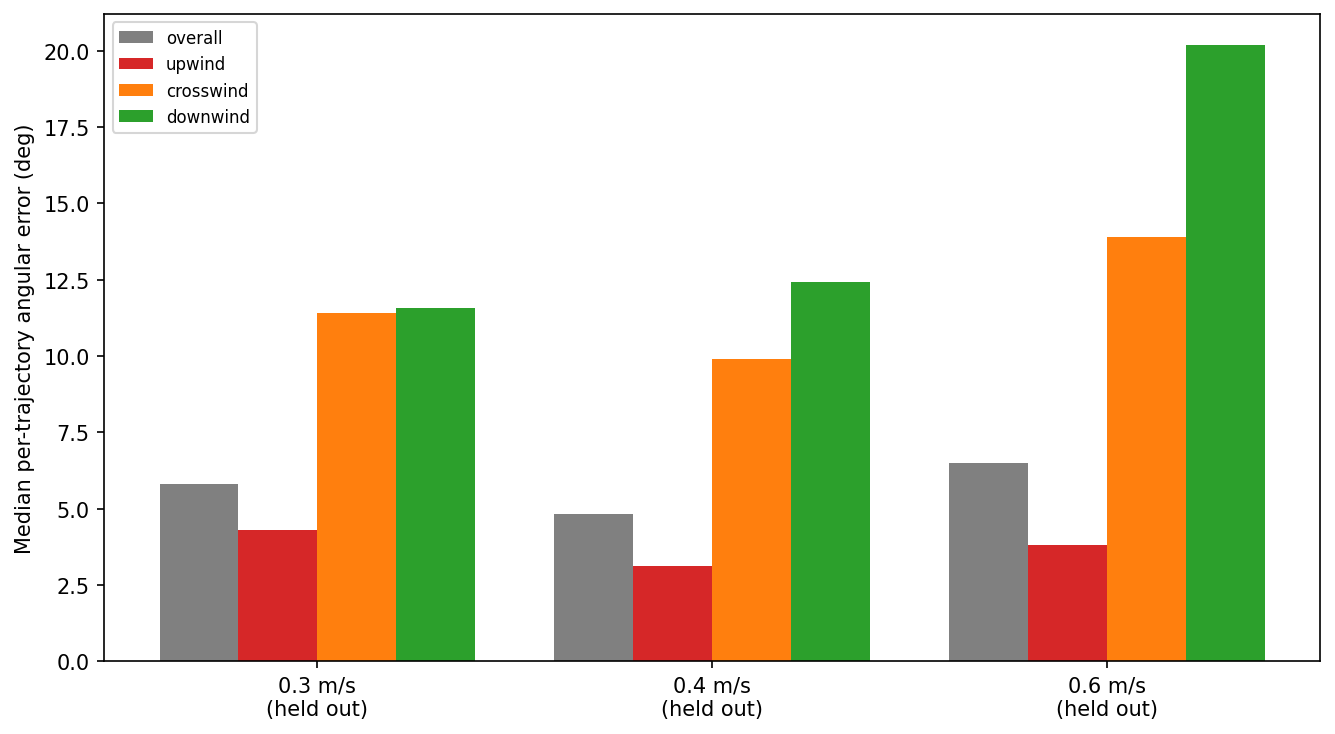

In [9]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
regimes_order = ['overall', 'upwind', 'crosswind', 'downwind']
x = np.arange(len(wind_conditions))
width = 0.2
bar_colors = ['gray', '#d62728', '#ff7f0e', '#2ca02c']
for i, reg in enumerate(regimes_order):
    vals = [lowo_table[(lowo_table['held_out_windspeed'] == w) & (lowo_table['regime'] == reg)]['median'].values[0]
            for w in wind_conditions]
    ax.bar(x + (i - 1.5) * width, vals, width, label=reg, color=bar_colors[i])
ax.set_xticks(x)
ax.set_xticklabels([f'{w} m/s\n(held out)' for w in wind_conditions])
ax.set_ylabel('Median per-trajectory angular error (deg)')
ax.legend(fontsize=8)
fig.tight_layout()
os.makedirs('../figures', exist_ok=True)
fig.savefig('../figures/leave_one_wind_out.svg', format='svg', bbox_inches='tight')
plt.show()

Leave-one-wind-speed-out generalizes well when 0.3 or 0.4 m/s is held out: overall median error stays close to the random-split result, and upwind flight stays comparably accurate in all three held-out conditions. Holding out 0.6 m/s degrades the crosswind and, most severely, the downwind regime, where the median error is large enough that predicted headings typically point closer to the wrong direction than the right one. This is expected, since the fastest wind condition produces downwind flight that the 0.3 and 0.4 m/s training data do not resemble.

Held-out accuracy is therefore not a guarantee of accuracy on a wind condition absent from training: a model that is sharper where it has relevant training signal is not more hedged where it has none. This motivates the confidence signal and input-range check later in this notebook, which are meant to flag predictions that should not be trusted.

#### Stratified Error vs. Kinematic Covariates

For each held-out test trajectory (from the canonical model evaluated on the held-out
test set above), we compute a small set of per-trajectory summary covariates -- mean airspeed, mean
groundspeed, mean thrust magnitude, maximum turning rate, mean absolute slip angle (the angle
between heading and airspeed direction), and wind speed -- and relate each to the
trajectory's median ANN error. Continuous covariates are binned into deciles; wind speed
(only three discrete levels) is shown as a box plot.

n trajectories with covariates: 1096
Mean airspeed (m/s): Spearman rho = -0.507
Mean groundspeed (m/s): Spearman rho = -0.525
Mean thrust magnitude: Spearman rho = -0.472
Max turning rate (deg/frame): Spearman rho = 0.579
Mean |slip angle| (deg): Spearman rho = 0.731
windspeed=0.3: median=4.88 deg, n=396
windspeed=0.4: median=4.69 deg, n=368
windspeed=0.6: median=5.08 deg, n=332


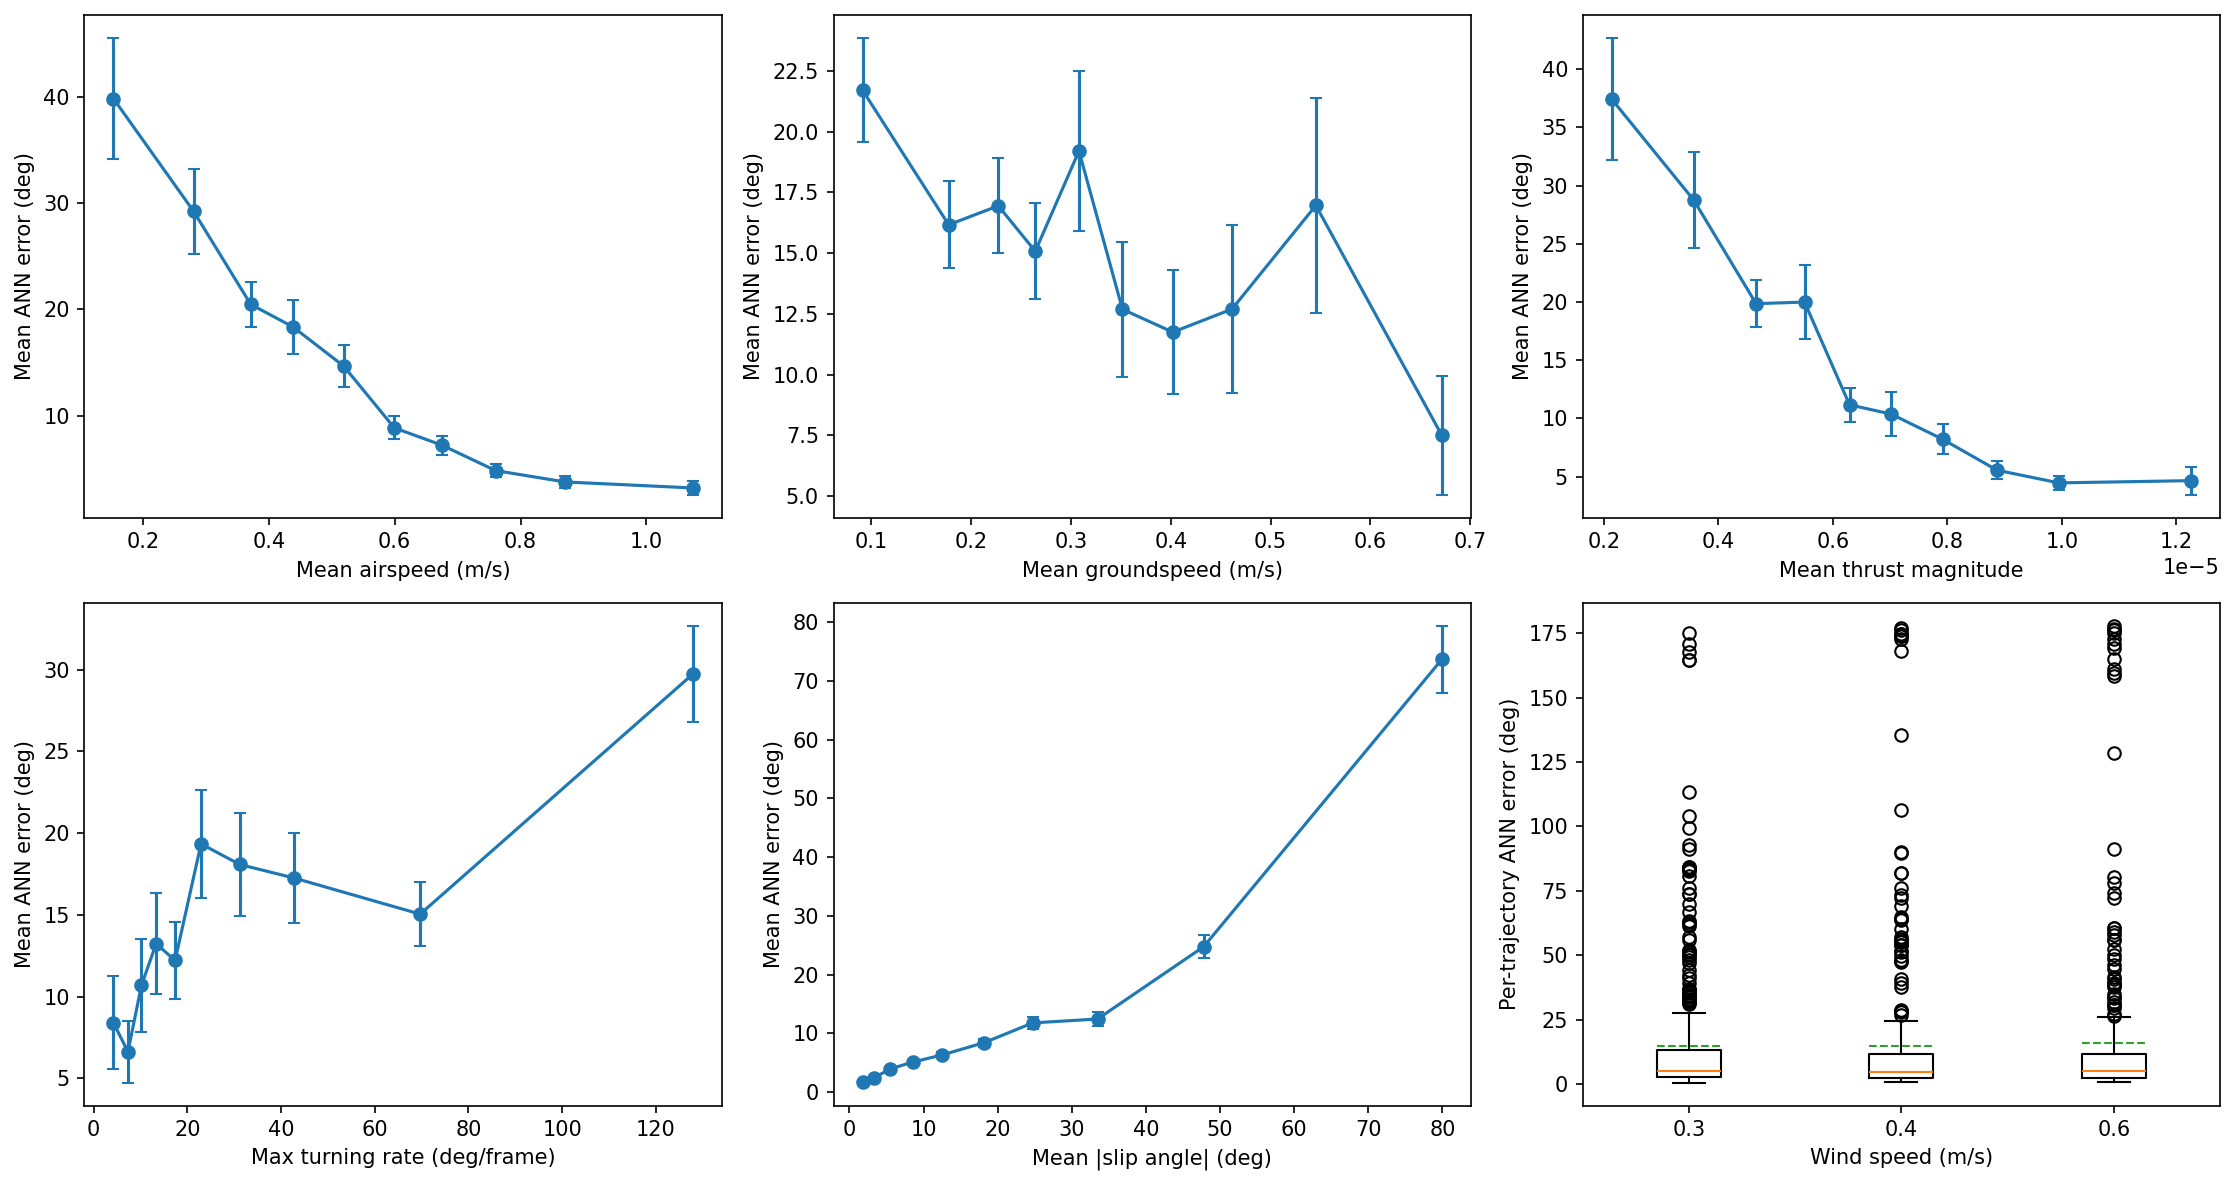

In [10]:
cov_rows = []
for t in fly_traj_list:
    tid = t['trajec_objid'].iloc[0]
    heading = t['heading_angle'].values
    turning_rate = np.degrees(np.abs(circular_distance(heading[1:], heading[:-1]))) if len(heading) > 1 else np.array([0.0])
    slip = np.degrees(np.abs(circular_distance(t['heading_angle'].values, t['airspeed_angle'].values)))
    cov_rows.append({
        'trajec_objid': tid,
        'mean_airspeed': t['airspeed'].mean(),
        'mean_groundspeed': t['groundspeed'].mean(),
        'mean_thrust': t['thrust'].mean(),
        'max_turning_rate': turning_rate.max(),
        'mean_slip_angle': slip.mean(),
        'windspeed': t['windspeed'].iloc[0],
    })
# One row per trajectory id (the nearest-timestamp merge leaves no id split into sub-segments;
# drop_duplicates only guards the per-trajectory merge below).
cov_df = pd.DataFrame(cov_rows).drop_duplicates(subset='trajec_objid', keep='first')

per_traj_err = ann_frame_df.groupby('trajec_objid')['err'].median().reset_index()
merged = per_traj_err.merge(cov_df, on='trajec_objid', how='inner')
os.makedirs('../tables', exist_ok=True)
merged.to_csv('../tables/ann_error_with_covariates.csv', index=False)
print(f"n trajectories with covariates: {len(merged)}")

covariates = [
    ('mean_airspeed', 'Mean airspeed (m/s)'),
    ('mean_groundspeed', 'Mean groundspeed (m/s)'),
    ('mean_thrust', 'Mean thrust magnitude'),
    ('max_turning_rate', 'Max turning rate (deg/frame)'),
    ('mean_slip_angle', 'Mean |slip angle| (deg)'),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), dpi=150)
axes = axes.flatten()
for ax, (col, label) in zip(axes, covariates):
    merged['decile'] = pd.qcut(merged[col], 10, labels=False, duplicates='drop')
    dec = merged.groupby('decile').agg(x=(col, 'mean'), y=('err', 'mean'), yerr=('err', 'sem')).reset_index()
    ax.errorbar(dec['x'], dec['y'], yerr=dec['yerr'], marker='o', capsize=3)
    ax.set_xlabel(label)
    ax.set_ylabel('Mean ANN error (deg)')
    rho = merged[col].corr(merged['err'], method='spearman')
    print(f"{label}: Spearman rho = {rho:.3f}")

ax = axes[5]
ws_levels = sorted(merged['windspeed'].unique())
ws_groups = [merged.loc[merged['windspeed'] == w, 'err'].values for w in ws_levels]
ax.boxplot(ws_groups, tick_labels=[str(w) for w in ws_levels], showmeans=True, meanline=True)
ax.set_xlabel('Wind speed (m/s)')
ax.set_ylabel('Per-trajectory ANN error (deg)')
for w in ws_levels:
    vals = merged.loc[merged['windspeed'] == w, 'err']
    print(f"windspeed={w}: median={vals.median():.2f} deg, n={len(vals)}")

fig.tight_layout()
fig.savefig('../figures/stratified_error_covariates.svg', format='svg', bbox_inches='tight')
plt.show()

Mean slip angle, or the angular offset between body heading and airspeed direction, is the strongest single correlate of ANN error: trajectories where the fly's body points far from its direction of travel through the air are hardest to predict, since this is where heading is least redundant with the model's four kinematic inputs. Maximum turning rate is the next strongest positive correlate. The three magnitude-based covariates (airspeed, groundspeed, thrust) correlate negatively with error: higher-magnitude, more purposeful flight is easier to predict than near-stationary or drifting flight, where direction is poorly determined by magnitude-based cues. Wind speed itself shows little association with error within the random-split test set, so performance differences *between* wind speeds are small when the model is trained on a representative mix. This contrasts with the leave-one-wind-speed-out result above, where generalization *to* an entirely unseen wind speed (particularly 0.6 m/s) is not guaranteed by in-distribution performance.

## Reproducibility

This notebook explicitly reports the random seeds, software versions, learning rate, weight initialization, early-stopping procedure, selected epoch, regularization, whether features were standardized, and whether cross-validation respects trajectory grouping. All of this information is already in the code above; we collect it here for convenience.

**Random seeds.** `RANDOM_SEED = 42` controls the trajectory-grouped train/test split (`GroupShuffleSplit`), numpy's global RNG, and the canonical ANN's weight initialization (`keras.utils.set_random_seed(RANDOM_SEED)`). The *Model Robustness* section above additionally reports seeds 7, 13, 99, and 123. The internal train/validation subsplit (`grouped_inner_val_split_with_weights`) uses its own fixed seed (123) for every training run in this notebook -- including the architecture search, the leave-one-wind-out runs, and the multi-seed runs -- so that randomness is held constant while only the weight-initialization seed varies across the multi-seed study, isolating what changes to initialization alone.

**Software versions.** Python 3.12.12, keras 3.13.2, tensorflow 2.21.0, scikit-learn 1.8.0, numpy 2.4.3, pandas 3.0.1, scipy 1.17.1 (exact pins in `requirements.txt`).

**Architecture.** Fully connected, ReLU hidden layers; the number of layers and neurons is selected via a grouped 3-fold cross-validated search over 1-3 layers x 10-30 neurons (*Selecting the Architecture*, above).

**Loss function and sample weighting.** `utils.geodesic_loss` (the true angular distance between predicted and target unit vectors, not plain MSE), with each training frame weighted by `utils.trajectory_length_sample_weights` (1/length of its trajectory) so that every trajectory contributes equally to the loss regardless of how many frames it has.

**Optimizer / learning rate.** Adam with unmodified Keras defaults everywhere in this notebook: `learning_rate=0.001`, `beta_1=0.9`, `beta_2=0.999`, `epsilon=1e-7`. No learning-rate schedule or manual tuning is applied.

**Weight initialization.** Unmodified Keras `Dense` defaults: kernel = Glorot/Xavier uniform, bias = zeros.

**Early stopping / selected epoch.** None. Every model trained in this notebook -- the architecture search, the canonical ANN, all 5 multi-seed runs, and all 3 leave-one-wind-out runs -- is trained for exactly 150 fixed epochs with no `EarlyStopping` callback and no checkpoint selection; the reported model is always the state after the 150th epoch, regardless of the validation-loss trajectory.

**Regularization.** None. No dropout, no L2/L1 weight penalty, no batch normalization.

**Feature standardization.** Not applied. The four ANN inputs (groundspeed, groundspeed_angle, airspeed, airspeed_angle) are passed to the network in their raw physical units (m/s and radians), with no scaling or centering.

**Cross-validation / grouped splitting.** Every split in this notebook is trajectory-grouped, so no trajectory contributes frames to both sides of any split. The architecture search uses `GroupKFold` cross-validation (3 folds, keyed on `trajec_objid`); the outer train/test split uses `GroupShuffleSplit` (keyed on `trajec_objid`); and the inner train/validation split used during `model.fit` (`grouped_inner_val_split_with_weights`, also grouped by `trajec_objid`) is an explicit pre-split passed to `validation_data=`, rather than Keras's own random `validation_split` argument.

## Prediction Confidence and Out-of-Range Warnings

The model can fail in kinematically ambiguous conditions (see the regime and covariate analyses above: low airspeed, high slip angle and an unseen wind condition are all associated with much larger errors), so users need a way to identify which individual predictions are likely unreliable. Two tools are provided: an ensemble-agreement confidence signal built from the 5 independently seeded models trained above, and a utility that warns when new inputs fall outside the range of conditions the model was trained on.

#### Ensemble Agreement as a Confidence Signal

The 5 models from the *Model Robustness* section above differ only in weight initialization
and the internal train/validation subsplit -- they were not trained as a deliberate ensemble,
but they can be reused as one for free. For each test frame, we take all 5 models' predicted
heading as unit vectors and compute their mean resultant length `R` (the length of the
vector average of the 5 unit predictions): `R=1` means all 5 models agree exactly; `R` near 0
means they disagree substantially. We then check whether trajectories where the ensemble
disagrees are, in fact, the trajectories where the (seed=42) canonical model is most wrong.

In [11]:
from utils import register_geodesic_loss

register_geodesic_loss()  # needed to reload models trained with the custom geodesic_loss
ensemble_seeds = [42, 7, 13, 99, 123]
ensemble_models = {s: keras.models.load_model(f'../models/ensemble/ann_seed_{s}.keras') for s in ensemble_seeds}
ensemble_preds = {s: m(X_test.astype('float32'), training=False).numpy() for s, m in ensemble_models.items()}

# per-frame predicted heading angle for each ensemble member
pred_angles = np.column_stack([
    np.arctan2(ensemble_preds[s][:, 1], ensemble_preds[s][:, 0]) for s in ensemble_seeds
])

# per-frame mean resultant length R in [0, 1]: 1 = perfect agreement, 0 = scattered
cos_mean = np.mean(np.cos(pred_angles), axis=1)
sin_mean = np.mean(np.sin(pred_angles), axis=1)
R = np.sqrt(cos_mean ** 2 + sin_mean ** 2)

canonical_err = angular_error_deg(y_true_ann, ensemble_preds[42])  # the notebook's canonical (seed=42) model

agreement_df = pd.DataFrame({'trajec_objid': test_embedded['trajec_objid'].values, 'R': R, 'err': canonical_err})
per_traj_agreement = agreement_df.groupby('trajec_objid').agg(R=('R', 'median'), err=('err', 'median')).reset_index()
os.makedirs('../tables', exist_ok=True)
per_traj_agreement.to_csv('../tables/ann_ensemble_agreement.csv', index=False)

per_traj_agreement['quartile'] = pd.qcut(per_traj_agreement['R'], 4,
                                          labels=['Q1 (lowest agreement)', 'Q2', 'Q3', 'Q4 (highest agreement)'])
calib_table = per_traj_agreement.groupby('quartile', observed=True).agg(
    n=('err', 'size'), median_R=('R', 'median'), median_err=('err', 'median'), mean_err=('err', 'mean')
).reset_index()
print(calib_table.to_string(index=False))

overall_corr = per_traj_agreement['R'].corr(per_traj_agreement['err'], method='spearman')
print(f"\nSpearman correlation (agreement R vs. error): {overall_corr:.3f}")

              quartile   n  median_R  median_err  mean_err
 Q1 (lowest agreement) 274  0.998166   13.125918 32.186586
                    Q2 274  0.999104    5.193817 12.612575
                    Q3 274  0.999421    3.652936  7.652898
Q4 (highest agreement) 274  0.999707    2.363730  7.803956

Spearman correlation (agreement R vs. error): -0.543


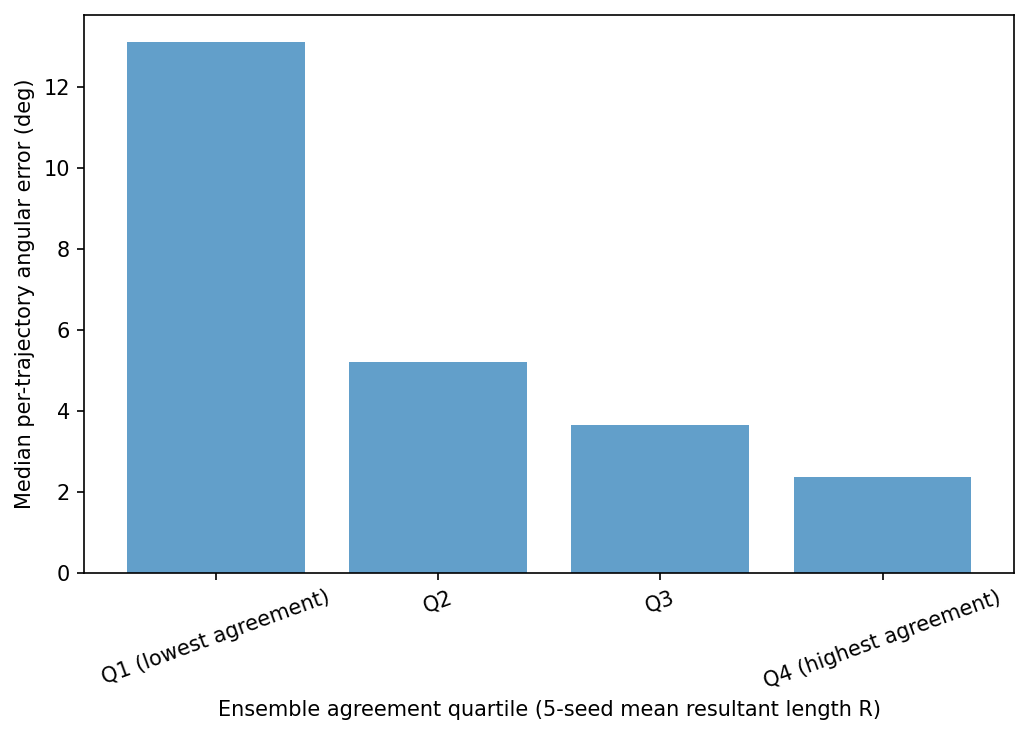

In [12]:
fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
ax.bar(calib_table['quartile'].astype(str), calib_table['median_err'], color='tab:blue', alpha=0.7)
ax.set_ylabel('Median per-trajectory angular error (deg)')
ax.set_xlabel('Ensemble agreement quartile (5-seed mean resultant length R)')
ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
os.makedirs('../figures', exist_ok=True)
fig.savefig('../figures/ensemble_agreement_calibration.svg', format='svg', bbox_inches='tight')
plt.show()

Ensemble disagreement is a usable confidence signal: error rises steadily from the highest-agreement quartile to the lowest, and the Spearman correlation between agreement and error is clearly negative. In practice, for any new trajectory, running all 5 saved ensemble models (`../models/ensemble/ann_seed_*.keras`) and checking how tightly their predicted headings cluster gives a per-trajectory (or per-frame) reliability estimate *without* needing ground truth. The correlation is far from perfect, so this should be read as a screening tool -- flagging trajectories for manual review or exclusion from high-stakes downstream analysis -- rather than a reliability guarantee. The signal also captures within-distribution ambiguity, not out-of-distribution extrapolation: in the leave-one-wind-out failure above (0.6 m/s downwind), ensemble members trained on the same 0.3/0.4 m/s data could agree with each other while still being collectively wrong. The input-range check below is therefore a complement to the ensemble signal, not a redundant one.

#### Out-of-Range Input Warnings

`utils.check_inputs_in_training_range` checks new magnitude-type inputs (groundspeed, airspeed; thrust if used) against the range observed in training and prints a warning for any row that falls outside it. The check is simple -- a bounding box on the raw feature ranges. Angular features (e.g. `groundspeed_angle`) are circular and excluded, since every direction was represented during training via the wind-rotation augmentation.

In [13]:
from utils import check_inputs_in_training_range

training_ranges = {
    'groundspeed': (train_df['groundspeed'].min(), train_df['groundspeed'].max()),
    'airspeed': (train_df['airspeed'].min(), train_df['airspeed'].max()),
}
print("Training ranges:", {k: (round(v[0], 4), round(v[1], 4)) for k, v in training_ranges.items()})

# Demonstration on a synthetic batch: two in-range rows, two out-of-range rows.
demo_groundspeed = np.array([0.3, 0.9, 2.5, 0.0001])
demo_airspeed = np.array([0.4, 1.0, 0.5, 3.0])
_ = check_inputs_in_training_range(
    {'groundspeed': demo_groundspeed, 'airspeed': demo_airspeed},
    training_ranges,
)

Training ranges: {'groundspeed': (0.0001, 1.3806), 'airspeed': (0.0021, 1.6755)}
  groundspeed: 1 row(s) out of range (training range [9.894e-05, 1.381])
  airspeed: 1 row(s) out of range (training range [0.002057, 1.676])


The check uses the minimum and maximum groundspeed and airspeed observed in the training trajectories; deployment on trajectories with substantially faster (or, for airspeed, near-zero) flight should be treated as extrapolation. Combined with the ensemble-agreement signal above, this gives two complementary ways to flag an unreliable prediction: `R` catches cases that are *kinematically ambiguous* even within the training distribution (e.g. high slip angle at an in-range airspeed), while `check_inputs_in_training_range` catches cases that are *outside the training distribution entirely* (e.g. a much faster flight regime than 0.3-0.6 m/s wind, or software applied to a different species or setup). Neither replaces validating against ground truth where it is available, but both are usable at inference time when it is not.

# ANN performance and errors

How well does the trained ANN (`../models/ann_model.keras`) predict heading on trajectories it has never seen, and where does it fail? It is evaluated on the held-out trajectories of the trajectory-grouped split above (seed 42, 33% test), using the saved model and the five-seed ensemble.

1. **ANN vs. the best linear predictor.** One held-out trajectory shown three ways: the ground-truth heading, the heading from the best baseline (the free-slope circular / Möbius regression on airspeed direction, see `03_ann_vs_linear_models.ipynb`) and the ANN's heading.
2. **ANN error analysis.** Error against slip angle, against the five-model ensemble's mean resultant length $R$, and for trajectories inside vs. outside the training set.

Error is the median per-trajectory angular error (deg).

## ANN and helpers

In [14]:
import matplotlib.colors as mcolors
from scipy.optimize import minimize
from scipy.stats import spearmanr

import fly_plot_lib_plot as fpl
from utils import augment_trajectories, register_geodesic_loss

MODEL_PATH = '../models/ann_model.keras'
RESULTS = '../tables/'
os.makedirs('../figures', exist_ok=True)

# same trajectory-grouped split as above (seed 42, 33% test)
data = final_all_fly_data
trajs = pull_out_individual_trajectories(data, min_traj_length=12)
train_trajs = [t.reset_index(drop=True) for t in trajs if t['trajec_objid'].iloc[0] in train_ids]
test_trajs  = [t.reset_index(drop=True) for t in trajs if t['trajec_objid'].iloc[0] in test_ids]
print(len(train_trajs), 'train trajectories,', len(test_trajs), 'held-out trajectories')

INPUTS = ['groundspeed', 'groundspeed_angle', 'airspeed', 'airspeed_angle']
KEEP = ['heading_angle_x', 'heading_angle_y', 'trajec_objid']
register_geodesic_loss()
ann = keras.models.load_model(MODEL_PATH)

def embed_ann(tl):
    return augment_trajectories(tl, input_names=INPUTS, output_names=KEEP)

def ann_heading(traj):
    '''ANN heading for every frame of one trajectory (first frame repeated, as in plot_trajectory_with_predicted_heading)'''
    emb = embed_ann([traj])
    p = ann(emb.iloc[:, :len(INPUTS)].values.astype('float32'), training=False).numpy()   # ann.predict can deadlock when called many times
    h = np.arctan2(p[:, 1], p[:, 0])
    return np.concatenate([np.full(len(traj) - len(h), h[0]), h])

def per_trajectory_error(tl):
    '''median angular error per trajectory (deg), same procedure as the training notebook'''
    emb = embed_ann(tl)
    p = ann(emb.iloc[:, :len(INPUTS)].values.astype('float32'), training=False).numpy()   # ann.predict can deadlock when called many times
    y = emb[['heading_angle_x', 'heading_angle_y']].values
    err = np.degrees(circular_distance(np.arctan2(y[:, 1], y[:, 0]), np.arctan2(p[:, 1], p[:, 0])))
    return pd.DataFrame({'trajec_objid': emb['trajec_objid'].values, 'err': err}).groupby('trajec_objid')['err'].median()

err_train = per_trajectory_error(train_trajs)
err_test = per_trajectory_error(test_trajs)
print(f'median error  train: {err_train.median():.2f} deg   held-out: {err_test.median():.2f} deg')

Detected 3321 trajectories.
3321 trajectories with more than 12 timesteps.
2225 train trajectories, 1096 held-out trajectories


median error  train: 4.85 deg   held-out: 4.91 deg


# Part 1 — ANN vs. the best linear predictor

## Möbius baseline (airspeed direction)

$\hat\theta = \mu + 2\arctan(\beta\tan\frac{\theta_{air}-\nu}{2})$, fit on the training trajectories by minimising $\sum(1-\cos e)$. This was the best baseline on the held-out set (`03_ann_vs_linear_models.ipynb`).

In [15]:
def circ_mean(a): return np.arctan2(np.sin(a).mean(), np.cos(a).mean())
def mobius(x, mu, nu, lb): return mu + 2 * np.arctan(np.exp(lb) * np.tan((x - nu) / 2))

def fit_mobius(x, y):
    best = None
    for nu0 in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        for lb0 in (-1.0, 0.0, 1.0, 2.0):
            r = minimize(lambda p: np.mean(1 - np.cos(y - mobius(x, *p))), [circ_mean(y - x), nu0, lb0],
                         method='Nelder-Mead', options=dict(xatol=1e-6, fatol=1e-10, maxiter=4000))
            if best is None or r.fun < best.fun: best = r
    return best.x

params = fit_mobius(train_df['airspeed_angle'].values, train_df['heading_angle'].values)
print(f'mu={params[0]:.3f}  nu={params[1]:.3f}  beta={np.exp(params[2]):.2f}')

mu=0.112  nu=6.371  beta=0.59


## Predictions on every held-out trajectory

In [16]:
rows, preds = [], {}
for t in test_trajs:
    tid = t['trajec_objid'].iloc[0]
    truth = t['heading_angle'].values
    h_ann = ann_heading(t)
    h_mob = mobius(t['airspeed_angle'].values, *params)
    e_ann = np.degrees(circular_distance(truth, h_ann)); e_mob = np.degrees(circular_distance(truth, h_mob))
    preds[tid] = (h_mob, h_ann)
    rows.append({'trajec_objid': tid, 'n_frames': len(t), 'ann_err': np.median(e_ann), 'mobius_err': np.median(e_mob),
                 'gap': np.median(e_mob) - np.median(e_ann), 'heading_range_deg': np.degrees(np.ptp(np.unwrap(truth)))})
res = pd.DataFrame(rows).drop_duplicates('trajec_objid')
print(res[['n_frames', 'ann_err', 'mobius_err', 'gap', 'heading_range_deg']].describe().round(1))

       n_frames  ann_err  mobius_err     gap  heading_range_deg
count    1096.0   1096.0      1096.0  1096.0             1096.0
mean       33.7     15.1        18.2     3.2               70.9
std        33.2     29.4        25.9    12.0               66.4
min        13.0      0.5         0.8  -128.0                3.2
25%        18.0      2.5         4.7    -0.0               22.1
50%        25.0      4.9         8.4     2.2               51.9
75%        37.0     12.2        18.6     5.6               95.4
max       561.0    177.8       174.5    96.3              535.7


## Choosing the example

The example should show the ANN accurate where the Möbius baseline is not, on a trajectory long enough to read and whose heading actually changes (not a straight upwind flight). Held-out trajectories are short, so the criteria are relaxed in steps until at least one trajectory qualifies. Ranked by the error gap, Möbius error minus ANN error.

In [17]:
LADDER = [(30, 4, 25, 90), (30, 5, 15, 90), (40, 5, 12, 60), (30, 5, 12, 45), (25, 6, 10, 30)]   # (min frames, max ANN err, min Mobius err, min heading range)
for nmin, a_max, m_min, r_min in LADDER:
    cand = res[res['n_frames'].between(nmin, 250) & (res['ann_err'] < a_max) & (res['mobius_err'] > m_min)
               & (res['heading_range_deg'] > r_min)].sort_values('gap', ascending=False)
    print(f'frames>={nmin}, ANN<{a_max}, Mobius>{m_min}, heading range>{r_min}: {len(cand)} candidate(s)')
    if len(cand): break
display(cand.head(10).round(2))

frames>=30, ANN<4, Mobius>25, heading range>90: 0 candidate(s)
frames>=30, ANN<5, Mobius>15, heading range>90: 3 candidate(s)


,trajec_objid,n_frames,ann_err,mobius_err,gap,heading_range_deg
375,20130327_193200_10522,35,4.82,22.63,17.81,138.90
401,20130327_193200_11852,44,4.44,19.57,15.13,151.10
323,20130325_193727_5264,34,4.70,15.64,10.95,535.72


In [18]:
TID = '20130327_193200_10522'   # top-ranked candidate from the ladder above (first step with a candidate); 20130327_193200_8714 before the Viterbi-corrected rerun
print('example:', TID)

example: 20130327_193200_10522


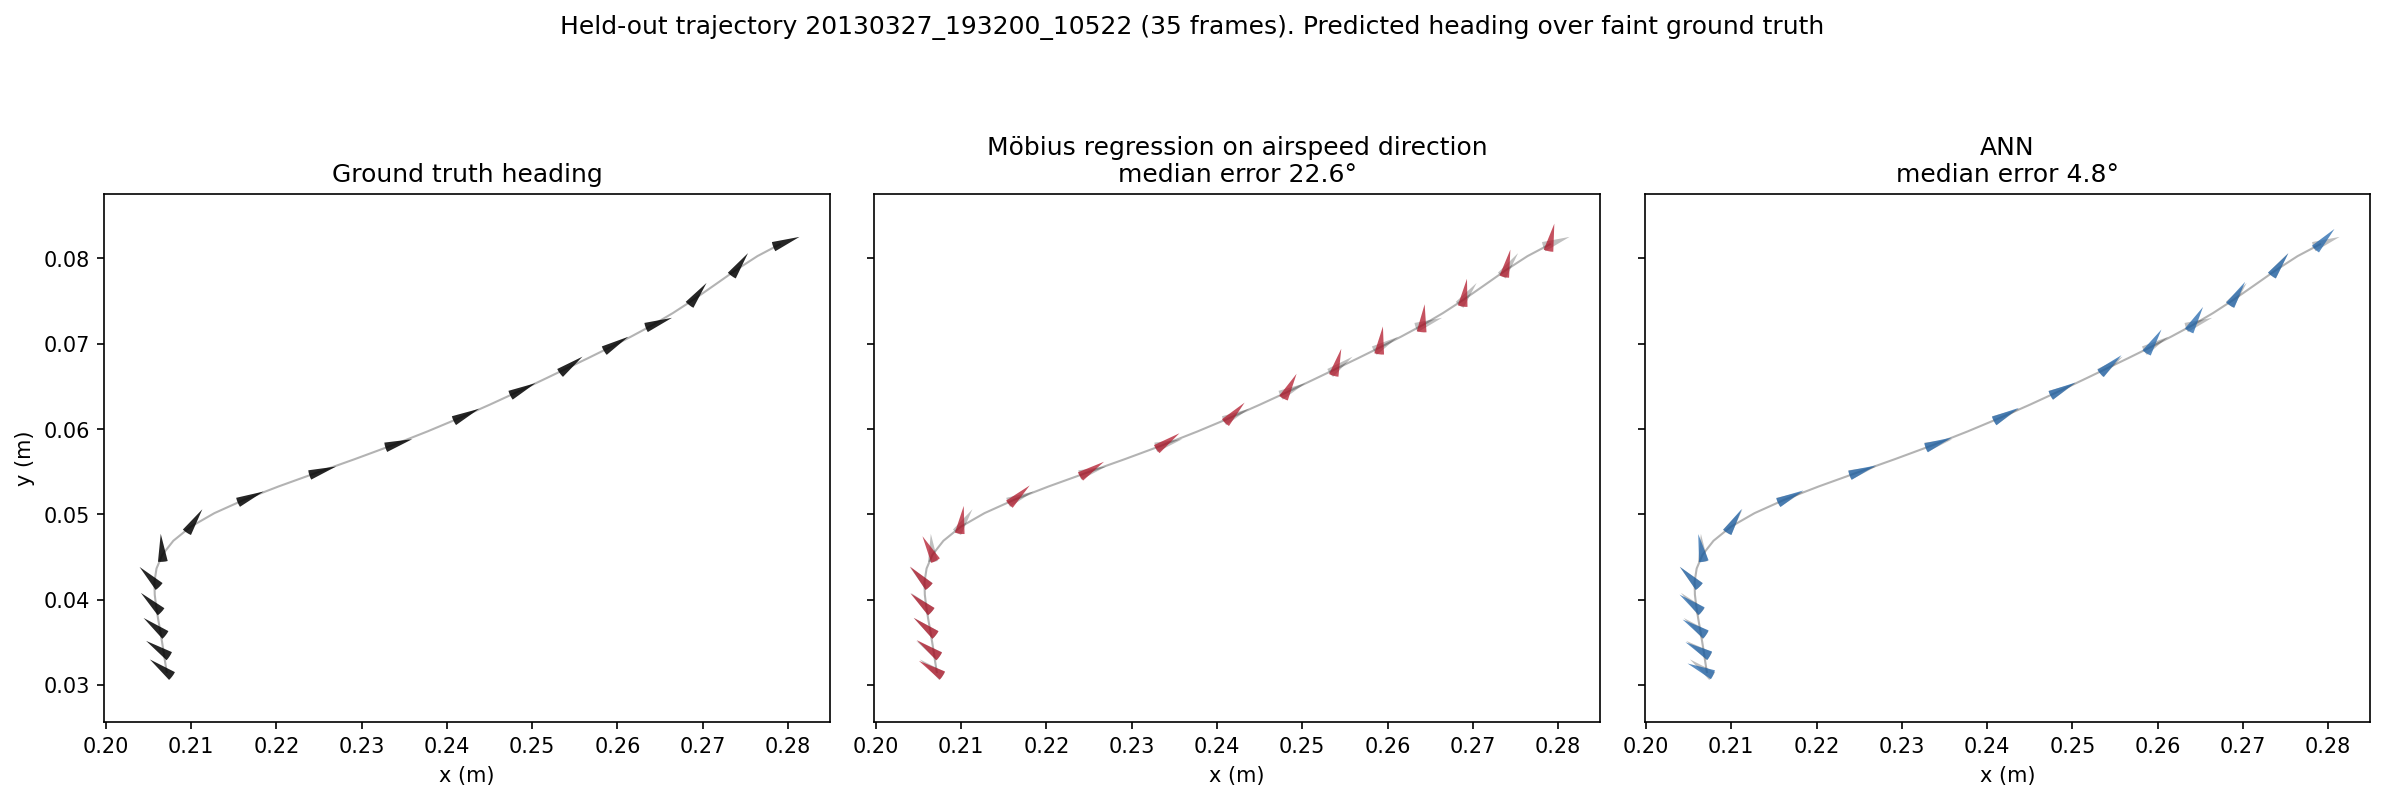

In [19]:
BLUE, RED, GREY = '#2166ac', '#b2182b', '#666666'

def draw_heading(ax, x, y, h, color, alpha, radius, every):
    cmap = mcolors.LinearSegmentedColormap.from_list('_c', [color, color])
    fpl.colorline_with_heading(ax, np.flip(x[::every]), np.flip(y[::every]), np.ones(len(x[::every])),
                               np.flip(h[::every]), nskip=0, size_radius=radius, deg=False, colormap=cmap,
                               center_point_size=0.0001, colornorm=[0, 1], show_centers=False,
                               size_angle=20, alpha=alpha, edgecolor='none')

t = next(t for t in test_trajs if t['trajec_objid'].iloc[0] == TID)
x, y, truth = t['position_x'].values, t['position_y'].values, t['heading_angle'].values
h_mob, h_ann = preds[TID]
r = res.set_index('trajec_objid').loc[TID]
extent = max(np.ptp(x), np.ptp(y)); radius = 0.045 * extent
every = max(2, len(t) // 28)
pad = 0.08 * extent

fig, axs = plt.subplots(1, 3, figsize=(16, 5.6), dpi=150, sharex=True, sharey=True)
panels = [('Ground truth heading', None, GREY, None),
          ('Möbius regression on airspeed direction', h_mob, RED, r['mobius_err']),
          ('ANN', h_ann, BLUE, r['ann_err'])]
for ax, (title, h, color, err) in zip(axs, panels):
    ax.plot(x, y, color='0.7', lw=1, zorder=1)
    if h is None:
        draw_heading(ax, x, y, truth, 'black', 0.85, radius, every)
    else:
        draw_heading(ax, x, y, truth, 'black', 0.25, radius, every)   # faint ground truth underneath
        draw_heading(ax, x, y, h, color, 0.75, radius, every)
    ax.set_aspect('equal')
    ax.set_xlim(x.min() - pad, x.max() + pad); ax.set_ylim(y.min() - pad, y.max() + pad)
    ax.set_title(title if err is None else f'{title}\nmedian error {err:.1f}°')
    ax.set_xlabel('x (m)')
axs[0].set_ylabel('y (m)')
fig.suptitle(f'Held-out trajectory {TID} ({len(t)} frames). Predicted heading over faint ground truth', y=1.0)
fig.tight_layout()
fig.savefig('../figures/ann_performance_example.pdf', bbox_inches='tight')
fig.savefig('../figures/ann_performance_example.png', dpi=300, bbox_inches='tight')
plt.show()

# Part 2 — ANN error analysis

- **A.** Error vs. mean slip angle (held-out trajectories).
- **B.** Error vs. the five-model ensemble's mean resultant length $R$ (held-out trajectories; $R=1$ means the five seeded models agree exactly).
- **C.** Error for trajectories inside vs. outside the training set.

In [20]:
# mean |slip angle| (body heading vs. airspeed direction) per trajectory
slip = {}
for tt in trajs:
    slip.setdefault(tt['trajec_objid'].iloc[0],
                    np.degrees(np.abs(circular_distance(tt['heading_angle'].values, tt['airspeed_angle'].values))).mean())
slip = pd.Series(slip, name='slip')
test_err = err_test.rename('err').to_frame().join(slip)

# five-seed ensemble mean resultant length per held-out trajectory (saved by the training notebook)
ens = pd.read_csv(RESULTS + 'ann_ensemble_agreement.csv').set_index('trajec_objid')
ens_df = ens[['R']].join(err_test.rename('err'), how='inner')
rho_slip = spearmanr(test_err['slip'], test_err['err'])
rho_R = spearmanr(ens_df['R'], ens_df['err'])
print(f'slip:  Spearman rho = {rho_slip.statistic:.3f}  (n = {len(test_err)})')
print(f'R:     Spearman rho = {rho_R.statistic:.3f}  (n = {len(ens_df)})')

slip:  Spearman rho = 0.731  (n = 1096)
R:     Spearman rho = -0.543  (n = 1096)


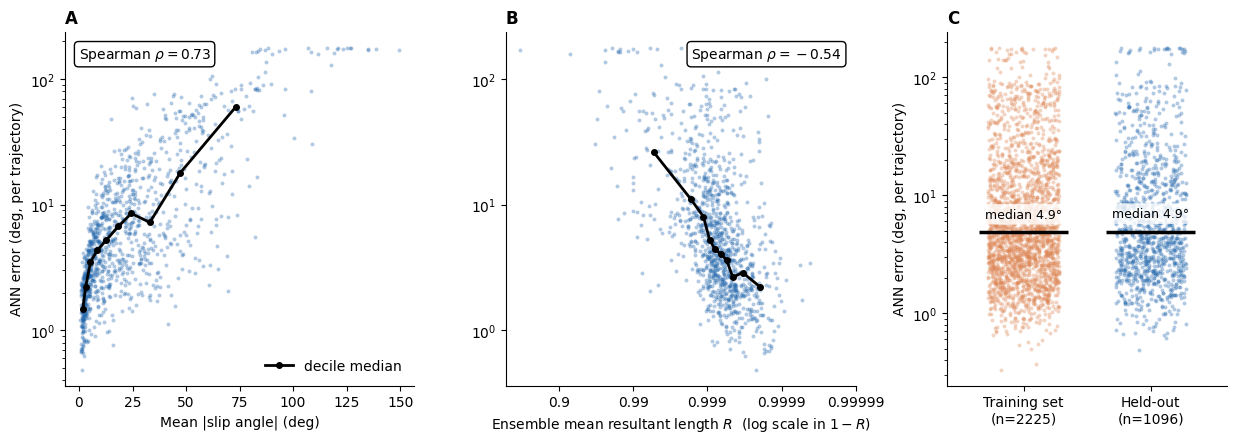

In [21]:
ORANGE = '#DD8452'
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.8], wspace=0.28))

def binned_median(ax, x, y, n=10, color='black'):
    b = pd.qcut(x, n, duplicates='drop')
    g = pd.DataFrame({'x': x, 'y': y, 'b': b}).groupby('b', observed=True).agg(x=('x', 'median'), y=('y', 'median'))
    ax.plot(g['x'], g['y'], '-o', color=color, lw=2, ms=4, label='decile median')

# A: error vs slip angle
ax = axes[0]
ax.scatter(test_err['slip'], test_err['err'], s=8, alpha=0.35, color=BLUE, lw=0, rasterized=True)
binned_median(ax, test_err['slip'], test_err['err'])
ax.set_yscale('log'); ax.set_xlabel('Mean |slip angle| (deg)'); ax.set_ylabel('ANN error (deg, per trajectory)')
ax.text(0.04, 0.96, rf'Spearman $\rho = {rho_slip.statistic:.2f}$', transform=ax.transAxes, va='top', bbox=dict(boxstyle='round', fc='white', ec='black'))
ax.legend(loc='lower right', frameon=False); ax.set_title('A', loc='left', fontweight='bold')

# B: error vs ensemble resultant length (R is crowded near 1, so plot 1 - R on a log axis, agreement to the right)
ax = axes[1]
d = (1 - ens_df['R']).clip(lower=1e-6)
ax.scatter(d, ens_df['err'], s=8, alpha=0.35, color=BLUE, lw=0, rasterized=True)
binned_median(ax, d, ens_df['err'])
ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
ticks = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
ax.set_xticks(ticks); ax.set_xticklabels([f'{1 - tk:g}' for tk in ticks]); ax.minorticks_off()
ax.set_xlabel('Ensemble mean resultant length $R$  (log scale in $1-R$)')
ax.text(0.96, 0.96, rf'Spearman $\rho = {rho_R.statistic:.2f}$', transform=ax.transAxes, va='top', ha='right', bbox=dict(boxstyle='round', fc='white', ec='black'))
ax.set_title('B', loc='left', fontweight='bold')

# C: inside vs outside the training set
ax = axes[2]
rng = np.random.default_rng(0)
for i, (name, e, c) in enumerate([('Training set', err_train, ORANGE), ('Held-out', err_test, BLUE)]):
    ax.scatter(i + rng.uniform(-0.28, 0.28, len(e)), e, s=8, alpha=0.35, color=c, lw=0, rasterized=True)
    ax.hlines(e.median(), i - 0.35, i + 0.35, color='black', lw=2.5)
    ax.text(i, e.median() * 1.25, f'median {e.median():.1f}°', ha='center', va='bottom', fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='none', alpha=0.8))
ax.set_yscale('log'); ax.set_xlim(-0.6, 1.6)
ax.set_xticks([0, 1]); ax.set_xticklabels([f'Training set\n(n={len(err_train)})', f'Held-out\n(n={len(err_test)})'])
ax.set_ylabel('ANN error (deg, per trajectory)'); ax.set_title('C', loc='left', fontweight='bold')

for a in axes: a.spines[['top', 'right']].set_visible(False)
fig.savefig('../figures/ann_performance_errors.pdf', bbox_inches='tight')
fig.savefig('../figures/ann_performance_errors.png', dpi=300, bbox_inches='tight')
plt.show()